
# 08 — Expanding vs. Rolling Training Windows

## 1. Introduction

This notebook investigates whether the length of the historical training period affects the accuracy of next-day electricity consumption forecasts in Basel-Stadt.

The exploratory analysis identified changes in electricity consumption levels over time. Furthermore, the expanding-window models developed in Notebooks 06 and 07 tended to overpredict consumption in 2025.

One possible explanation is that older observations reflect demand patterns that differ from more recent conditions.

We therefore compare two training strategies:

1. **Expanding window:** Training begins on 1 January 2018 and includes all subsequent eligible historical observations.
2. **Rolling three-year window:** Training uses only the most recent three years of eligible historical observations at each monthly refit.

We apply both strategies to:

- OLS regression with weather forecasts, using Person 2's specification.
- Random Forest regression, using the initial specification from Notebook 07.

### Evaluation methodology

- Target: next-day electricity consumption (MWh/day).
- Forecast deadline: 12:00 on the preceding day.
- Consumption availability assumption: `lag_5` and older.
- Validation period: January–December 2025.
- Validation procedure: 12 monthly chronological folds.
- Primary metric: MAE.
- Secondary metric: RMSE.
- Additional metric: mean signed error (actual minus predicted).

The model specifications, preprocessing procedures, features and validation dates remain unchanged across training-window strategies.

Only the historical training-window length changes.

The purpose is to determine whether recent observations improve predictive accuracy and reduce forecasting bias.

This notebook does not use the 2026 holdout.


## 2. Imports and project paths

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error
)


# Locate the repository
def find_repo_root(start):
    for folder in [start, *start.parents]:
        if (folder / "data" / "processed" / "features.csv").exists():
            return folder

    raise FileNotFoundError(
        "Could not find data/processed/features.csv"
    )


ROOT = find_repo_root(Path.cwd().resolve())

FEATURES_PATH = ROOT / "data" / "processed" / "features.csv"

TABLE_DIR = ROOT / "output" / "tables"
FIG_DIR = ROOT / "output" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


# Shared methodology
TRAIN_START = pd.Timestamp("2018-01-01")
MIN_LAG = 5

VALIDATION_MONTHS = pd.period_range(
    "2025-01",
    "2025-12",
    freq="M"
)

print("Repository:", ROOT)
print("Validation months:", len(VALIDATION_MONTHS))


Repository: /Users/laramileto/Documents/HSG/5° semestre /Workshop fundamentals DSF/group project/group_project/DSF_forecasting_electricity_consumption_Basel
Validation months: 12


## 3. Load the feature dataset

In [12]:
# Read the shared features

df = pd.read_csv(
    FEATURES_PATH,
    parse_dates=["date"]
)

df = df.sort_values("date").reset_index(drop=True)

# Restrict the working data to 2018–2025
# The final holdout must not influence model development.
df = df[
    (df["date"] >= TRAIN_START)
    & (df["date"] < pd.Timestamp("2026-01-01"))
].copy()

assert df["date"].is_unique
assert df["date"].is_monotonic_increasing

print("Development observations:", len(df))
print("First date:", df["date"].min().date())
print("Last date:", df["date"].max().date())

print("\nObservations by period:")
display(
    df.groupby("period")["date"].agg(
        first="min",
        last="max",
        days="count"
    )
)

print("\nMissing target observations:")
print(df["consumption_mwh"].isna().sum())


Development observations: 2922
First date: 2018-01-01
Last date: 2025-12-31

Observations by period:


,first,last,days
period,,,
train,2018-01-01,2024-12-31,2557
validation,2025-01-01,2025-12-31,365



Missing target observations:
0


## 4. Define the two training windows

For every validation month, the model is refitted at noon on the preceding month's final day.

The most recent eligible historical consumption target is defined as:

**Latest eligible target = first day of validation month − 5 calendar days.**

We compare:

### Expanding window

Training starts on 1 January 2018 and ends at the monthly eligibility cutoff.

### Rolling three-year window

Training includes the three-year calendar interval ending at the same eligibility cutoff.

The rolling window is measured using calendar dates rather than a fixed number of rows. This ensures that missing dates do not change the intended duration of the training period.

Both strategies predict exactly the same days in each validation month.


In [13]:
def get_window_fold(month, window="expanding"):
    """
    Return training and validation observations for
    one month using either an expanding window or
    a rolling three-year window.
    """

    first_day = month.start_time
    last_day = month.end_time.normalize()

    # Latest eligible consumption target
    cutoff = first_day - pd.Timedelta(days=MIN_LAG)

    if window == "expanding":

        training_start = TRAIN_START

    elif window == "rolling_3y":

        # Three calendar years, inclusive of the cutoff
        training_start = (
            cutoff
            - pd.DateOffset(years=3)
            + pd.Timedelta(days=1)
        )

    else:
        raise ValueError(
            "window must be 'expanding' or 'rolling_3y'"
        )

    train = df[
        (df["date"] >= training_start)
        & (df["date"] <= cutoff)
    ].copy()

    valid = df[
        (df["date"] >= first_day)
        & (df["date"] <= last_day)
    ].copy()

    # Checks
    assert len(train) > 0
    assert len(valid) > 0

    assert train["date"].min() >= training_start
    assert train["date"].max() <= cutoff
    assert train["date"].max() < valid["date"].min()

    assert (valid["period"] == "validation").all()

    return train, valid, cutoff


# Inspect both training strategies

window_records = []

for month in VALIDATION_MONTHS:

    for window in ["expanding", "rolling_3y"]:

        train, valid, cutoff = get_window_fold(
            month,
            window=window
        )

        window_records.append({
            "validation_month": str(month),
            "window": window,
            "training_start": train["date"].min(),
            "training_end": train["date"].max(),
            "n_training_days": len(train),
            "n_validation_days": len(valid),
        })


window_table = pd.DataFrame(window_records)

display(window_table)

# Confirm both strategies predict identical dates
for month in VALIDATION_MONTHS:

    _, expanding_valid, _ = get_window_fold(
        month, "expanding"
    )

    _, rolling_valid, _ = get_window_fold(
        month, "rolling_3y"
    )

    assert expanding_valid["date"].equals(
        rolling_valid["date"]
    )

print("\nAll validation dates match across windows.")


,validation_month,window,training_start,training_end,n_training_days,n_validation_days
0,2025-01,expanding,2018-01-01,2024-12-27,2553,31
1,2025-01,rolling_3y,2021-12-28,2024-12-27,1096,31
2,2025-02,expanding,2018-01-01,2025-01-27,2584,28
3,2025-02,rolling_3y,2022-01-28,2025-01-27,1096,28
4,2025-03,expanding,2018-01-01,2025-02-24,2612,31
5,2025-03,rolling_3y,2022-02-25,2025-02-24,1096,31
6,2025-04,expanding,2018-01-01,2025-03-27,2643,30
7,2025-04,rolling_3y,2022-03-28,2025-03-27,1096,30
8,2025-05,expanding,2018-01-01,2025-04-26,2673,31
9,2025-05,rolling_3y,2022-04-27,2025-04-26,1096,31



All validation dates match across windows.


## 5. Recreate the shared model features

In [14]:
TARGET = "consumption_mwh"

LAG_FEATURES = [
    "lag_5",
    "lag_6",
    "lag_7",
    "lag_14",
    "lag_21",
    "lag_28",
    "lag_mean_5_11",
]

WEATHER_FEATURES = [
    "heating_degrees",
    "cooling_degrees",
    "forecast_precipitation",
]

CATEGORICAL_FEATURES = [
    "weekday",
    "month",
]

BINARY_FEATURES = [
    "is_holiday",
    "is_christmas_period",
    "lag_7_is_holiday",
    "lag_14_is_holiday",
]

NUMERIC_FEATURES = LAG_FEATURES + WEATHER_FEATURES

FEATURES = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
    + BINARY_FEATURES
)

assert len(FEATURES) == 16
assert all(col in df.columns for col in FEATURES)

print("Number of model predictors:", len(FEATURES))


Number of model predictors: 16


## 6. Recreate OLS and Random Forest

In [15]:
def make_ols_pipeline():

    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAL_FEATURES
        ),
        (
            "binary",
            "passthrough",
            BINARY_FEATURES
        ),
    ])

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LinearRegression())
    ])


def make_rf_pipeline():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAL_FEATURES
        ),
        (
            "binary",
            "passthrough",
            BINARY_FEATURES
        ),
    ])

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=3,
            max_features=1.0,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        ))
    ])


print("OLS pipeline defined.")
print("Random Forest pipeline defined.")


OLS pipeline defined.
Random Forest pipeline defined.


## 7. Run the four model/window combinations

In [16]:
# Four configurations:
# OLS × expanding/rolling
# Random Forest × expanding/rolling

MODEL_FACTORIES = {
    "ols": make_ols_pipeline,
    "random_forest": make_rf_pipeline,
}

WINDOWS = [
    "expanding",
    "rolling_3y",
]

all_predictions = []

for model_name, model_factory in MODEL_FACTORIES.items():

    for window in WINDOWS:

        for month in VALIDATION_MONTHS:

            train, valid, cutoff = get_window_fold(
                month,
                window=window
            )

            model = model_factory()

            model.fit(
                train[FEATURES],
                train[TARGET]
            )

            predicted = model.predict(
                valid[FEATURES]
            )

            assert np.isfinite(predicted).all()

            fold_predictions = pd.DataFrame({
                "date": valid["date"].to_numpy(),
                "model": f"{model_name}_{window}",
                "validation_month": str(month),
                "actual_mwh": valid[TARGET].to_numpy(),
                "predicted_mwh": predicted,
            })

            all_predictions.append(fold_predictions)

            print(
                f"{model_name} | {window} | {month} | "
                f"training days: {len(train)}"
            )


window_predictions = pd.concat(
    all_predictions,
    ignore_index=True
)

window_predictions["prediction_error_mwh"] = (
    window_predictions["actual_mwh"]
    - window_predictions["predicted_mwh"]
)

window_predictions["absolute_error_mwh"] = (
    window_predictions["prediction_error_mwh"].abs()
)

# Four configurations × 365 validation days
assert len(window_predictions) == 4 * 365

assert (
    window_predictions.groupby("model")["date"].nunique()
    == 365
).all()

print("\nAll four configurations evaluated successfully.")

display(window_predictions.head())


ols | expanding | 2025-01 | training days: 2553
ols | expanding | 2025-02 | training days: 2584
ols | expanding | 2025-03 | training days: 2612
ols | expanding | 2025-04 | training days: 2643
ols | expanding | 2025-05 | training days: 2673
ols | expanding | 2025-06 | training days: 2704
ols | expanding | 2025-07 | training days: 2734
ols | expanding | 2025-08 | training days: 2765
ols | expanding | 2025-09 | training days: 2796
ols | expanding | 2025-10 | training days: 2826
ols | expanding | 2025-11 | training days: 2857
ols | expanding | 2025-12 | training days: 2887
ols | rolling_3y | 2025-01 | training days: 1096
ols | rolling_3y | 2025-02 | training days: 1096
ols | rolling_3y | 2025-03 | training days: 1096
ols | rolling_3y | 2025-04 | training days: 1096
ols | rolling_3y | 2025-05 | training days: 1096
ols | rolling_3y | 2025-06 | training days: 1096
ols | rolling_3y | 2025-07 | training days: 1096
ols | rolling_3y | 2025-08 | training days: 1096
ols | rolling_3y | 2025-09 | tra

,date,model,validation_month,actual_mwh,predicted_mwh,prediction_error_mwh,absolute_error_mwh
0,2025-01-01,ols_expanding,2025-01,3013.731878,2824.122864,189.609014,189.609014
1,2025-01-02,ols_expanding,2025-01,3404.135954,3482.379383,-78.243429,78.243429
2,2025-01-03,ols_expanding,2025-01,3461.485897,3428.432226,33.053671,33.053671
3,2025-01-04,ols_expanding,2025-01,3260.406578,3077.830703,182.575875,182.575875
4,2025-01-05,ols_expanding,2025-01,3061.128570,2750.111470,311.017100,311.017100


## 8. Calculate the results

In [17]:
def compute_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    assert len(actual) == len(predicted) > 0
    assert np.isfinite(actual).all()
    assert np.isfinite(predicted).all()

    return {
        "n_days": len(actual),
        "mae_mwh": mean_absolute_error(actual, predicted),
        "rmse_mwh": root_mean_squared_error(actual, predicted),
        "mean_error_mwh": np.mean(actual - predicted),
    }


window_results = []

for model_name, group in window_predictions.groupby("model"):

    metrics = compute_metrics(
        group["actual_mwh"],
        group["predicted_mwh"]
    )

    window_results.append({
        "model": model_name,
        **metrics
    })


window_results = pd.DataFrame(window_results)

print("2025 validation — Training-window results")

display(window_results.round(2))


2025 validation — Training-window results


,model,n_days,mae_mwh,rmse_mwh,mean_error_mwh
0,ols_expanding,365,80.36,105.44,-23.15
1,ols_rolling_3y,365,74.64,97.66,-25.59
2,random_forest_expanding,365,86.79,115.27,-21.64
3,random_forest_rolling_3y,365,81.66,104.18,-11.89



## 9. Results: Effect of Training-Window Length

We compare expanding and rolling three-year training windows for OLS and Random Forest.

Both models achieve lower MAE and RMSE with the rolling window. However, the effect on mean signed error differs: rolling training reduces average overprediction for Random Forest but not for OLS.

The comparison isolates training-window length by keeping the model specifications, explanatory variables, monthly refit dates and validation observations unchanged.


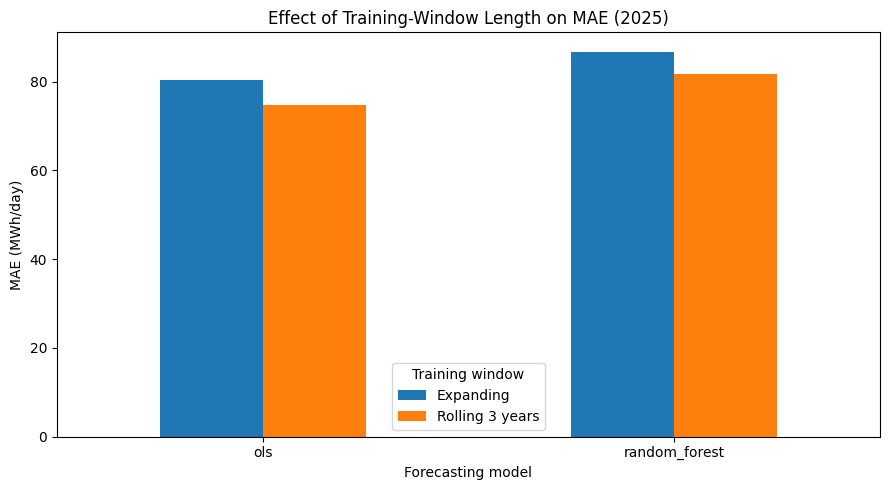

In [18]:
# Compare the two training strategies within each model family

plot_data = window_results.copy()

plot_data["model_family"] = (
    plot_data["model"]
    .str.replace("_rolling_3y", "", regex=False)
    .str.replace("_expanding", "", regex=False)
)

plot_data["window"] = np.where(
    plot_data["model"].str.endswith("_rolling_3y"),
    "Rolling 3 years",
    "Expanding"
)

mae_plot = plot_data.pivot(
    index="model_family",
    columns="window",
    values="mae_mwh"
)

mae_plot = mae_plot[["Expanding", "Rolling 3 years"]]

ax = mae_plot.plot.bar(
    figsize=(9, 5),
    rot=0
)

ax.set_title("Effect of Training-Window Length on MAE (2025)")
ax.set_xlabel("Forecasting model")
ax.set_ylabel("MAE (MWh/day)")
ax.legend(title="Training window")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "training_windows_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#### 9.1 Quantify the improvement

In [19]:
window_effects = []

for family in ["ols", "random_forest"]:

    expanding = window_results.loc[
        window_results["model"] == f"{family}_expanding"
    ].iloc[0]

    rolling = window_results.loc[
        window_results["model"] == f"{family}_rolling_3y"
    ].iloc[0]

    window_effects.append({
        "model_family": family,
        "expanding_mae": expanding["mae_mwh"],
        "rolling_mae": rolling["mae_mwh"],
        "mae_reduction_mwh": (
            expanding["mae_mwh"] - rolling["mae_mwh"]
        ),
        "mae_reduction_pct": (
            100 * (
                1 - rolling["mae_mwh"] / expanding["mae_mwh"]
            )
        ),
        "expanding_mean_error": expanding["mean_error_mwh"],
        "rolling_mean_error": rolling["mean_error_mwh"],
    })

window_effects = pd.DataFrame(window_effects)

display(window_effects.round(2))


,model_family,expanding_mae,rolling_mae,mae_reduction_mwh,mae_reduction_pct,expanding_mean_error,rolling_mean_error
0,ols,80.36,74.64,5.71,7.11,-23.15,-25.59
1,random_forest,86.79,81.66,5.13,5.91,-21.64,-11.89


## 10. Export

In [20]:
# Export daily predictions using the group's common format

export_columns = [
    "date",
    "model",
    "validation_month",
    "actual_mwh",
    "predicted_mwh",
    "prediction_error_mwh",
    "absolute_error_mwh",
]

window_predictions[export_columns].to_csv(
    TABLE_DIR / "training_windows_validation.csv",
    index=False
)

window_results.to_csv(
    TABLE_DIR / "training_windows_metrics.csv",
    index=False
)

window_effects.to_csv(
    TABLE_DIR / "training_windows_effects.csv",
    index=False
)

window_table.to_csv(
    TABLE_DIR / "training_windows_fold_information.csv",
    index=False
)

print("Exported 4 files for Person 4.")
print("Prediction rows:", len(window_predictions))

assert len(window_predictions) == 1460


Exported 4 files for Person 4.
Prediction rows: 1460



## 12. Conclusion

This notebook investigated whether the length of the historical training period affects next-day electricity consumption forecasting accuracy in Basel-Stadt.

We compared expanding and rolling three-year training windows for OLS regression with weather forecasts and Random Forest regression, using the same 12 monthly validation folds in 2025.

### Forecasting accuracy

**OLS regression**

- Expanding-window MAE: 80.36 MWh/day
- Rolling-window MAE: 74.64 MWh/day
- Reduction in MAE: approximately 7.1%

**Random Forest**

- Expanding-window MAE: 86.79 MWh/day
- Rolling-window MAE: 81.66 MWh/day
- Reduction in MAE: approximately 5.9%

Both models also achieved lower RMSE with rolling-window training.

### Forecasting bias

Using the signed error definition (actual − predicted), negative values indicate overprediction.

For OLS, mean error changed from −23.15 to −25.59 MWh/day. Therefore, the rolling window slightly increased average overprediction despite improving MAE.

For Random Forest, mean error changed from −21.64 to −11.89 MWh/day. Thus, the rolling window reduced average overprediction.

### Interpretation

These results indicate that using more recent historical observations improved forecasting accuracy for both evaluated model specifications during 2025.

One possible explanation is that older training observations reflect different electricity consumption patterns. However, this analysis does not establish a causal explanation for the improvement.

The rolling-window results are based on one validation year and may not generalize to other periods.

### Implications

The results support considering rolling three-year training as a candidate strategy for the final forecasting models.

The OLS rolling-window configuration achieved the lowest MAE among the four specifications evaluated in this notebook.

The final comparison and model selection will be coordinated by Person 4, using the common 2025 validation results.

The 2026 holdout remains untouched.
